In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

In [10]:
DB_PATH = Path("../datos/prueba_completa.sqlite").resolve()  # ajustar si es necesario

assert DB_PATH.exists(), f"No existe la base de datos: {DB_PATH}"

DB_PATH

WindowsPath('C:/Users/lrenzullis/Desktop/REFIGURA/audiovisuales/datos/prueba_completa.sqlite')

In [18]:
con = sqlite3.connect(
    f"{DB_PATH.as_uri()}?mode=ro",
    uri=True
)

In [19]:
tables = pd.read_sql_query(
    """
    SELECT name, type
    FROM sqlite_master
    WHERE type IN ('table', 'view')
    ORDER BY type, name
    """,
    con
)

display(tables)

,name,type
0,comentarios,table
1,ingestas,table
2,paginas_crudas,table


In [7]:
def query(sql, params=None):
    return pd.read_sql_query(
        sql,
        con,
        params=params
    )

In [20]:
duplicates = query("""
    SELECT
        COUNT(*) AS duplicated_ids
    FROM (
        SELECT
            video_id,
            comment_id
        FROM comentarios
        GROUP BY video_id, comment_id
        HAVING COUNT(*) > 1
    )
""")

duplicates

,duplicated_ids
0,0


In [21]:
comments_by_year = query("""
    SELECT
        CAST(strftime('%Y', published_at) AS INTEGER) AS year,
        COUNT(*) AS n_comments
    FROM comentarios
    GROUP BY year
    ORDER BY year
""")

comments_by_year

,year,n_comments
0,2022,15034
1,2023,575
2,2024,242
3,2025,96
4,2026,75


In [22]:
comments_by_year = query("""
    SELECT
        CAST(strftime('%Y', published_at) AS INTEGER) AS year,
        COUNT(*) AS n_comments,
        ROUND(
            100.0 * COUNT(*) /
            (SELECT COUNT(*) FROM comentarios),
            2
        ) AS pct
    FROM comentarios
    GROUP BY year
    ORDER BY year
""")

comments_by_year

,year,n_comments,pct
0,2022,15034,93.83
1,2023,575,3.59
2,2024,242,1.51
3,2025,96,0.60
4,2026,75,0.47


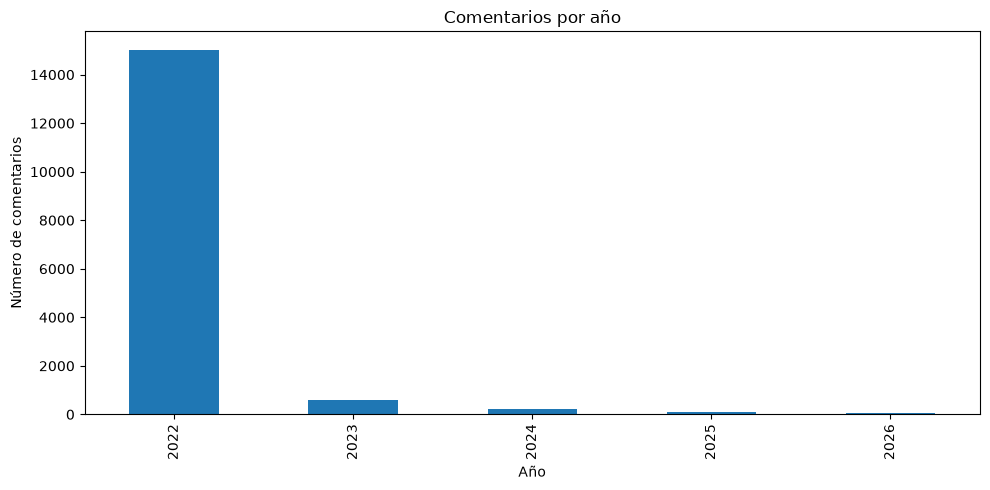

In [23]:
comments_by_year.plot(
    x="year",
    y="n_comments",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Comentarios por año")
plt.xlabel("Año")
plt.ylabel("Número de comentarios")
plt.tight_layout()
plt.show()

In [24]:
comments_by_month = query("""
    SELECT
        strftime('%Y-%m', published_at) AS month,
        COUNT(*) AS n_comments
    FROM comentarios
    GROUP BY month
    ORDER BY month
""")

comments_by_month.head()

,month,n_comments
0,2022-08,11109
1,2022-09,3349
2,2022-10,329
3,2022-11,139
4,2022-12,108


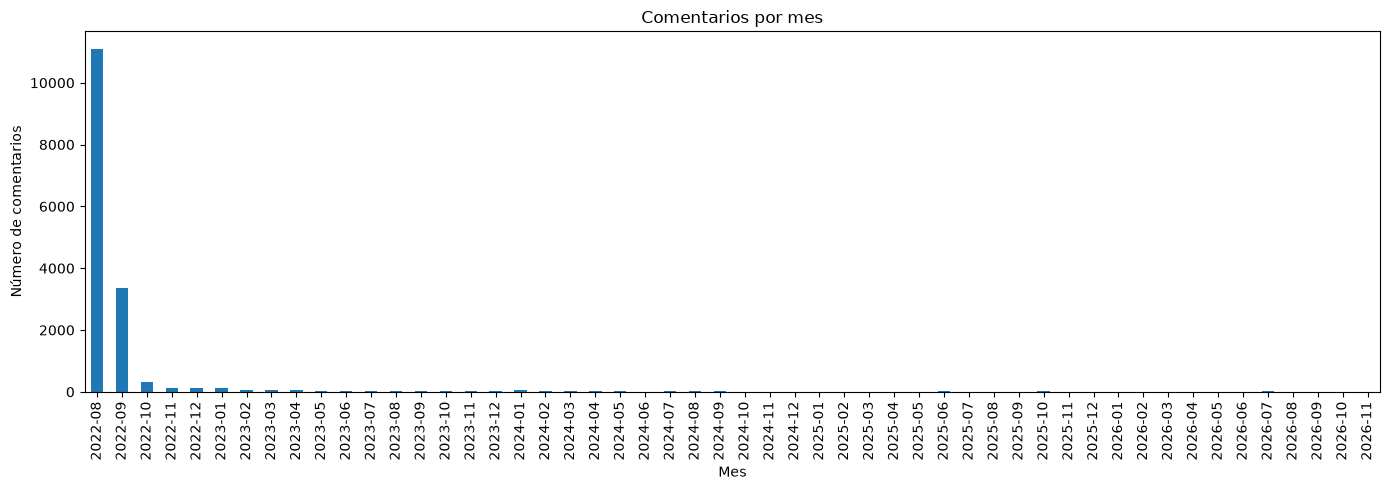

In [25]:
comments_by_month.plot(
    x="month",
    y="n_comments",
    kind="bar",
    figsize=(14, 5),
    legend=False
)

plt.title("Comentarios por mes")
plt.xlabel("Mes")
plt.ylabel("Número de comentarios")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [26]:
comments_by_day = query("""
    SELECT
        DATE(published_at) AS date,
        COUNT(*) AS n_comments
    FROM comentarios
    GROUP BY DATE(published_at)
    ORDER BY date
""")

comments_by_day

,date,n_comments
0,2022-08-23,5686
1,2022-08-24,2111
2,2022-08-25,733
3,2022-08-26,606
4,2022-08-27,410
...,...,...
672,2026-10-13,1
673,2026-10-27,2
674,2026-11-01,1
675,2026-11-04,1


In [27]:
activity_peaks = query("""
    SELECT
        DATE(published_at) AS date,
        COUNT(*) AS n_comments
    FROM comentarios
    GROUP BY DATE(published_at)
    ORDER BY n_comments DESC
    LIMIT 20
""")

activity_peaks

,date,n_comments
0,2022-08-23,5686
1,2022-08-24,2111
2,2022-08-25,733
3,2022-08-26,606
4,2022-08-29,469
5,2022-09-02,443
6,2022-08-27,410
7,2022-08-28,407
8,2022-08-30,402
9,2022-09-04,401


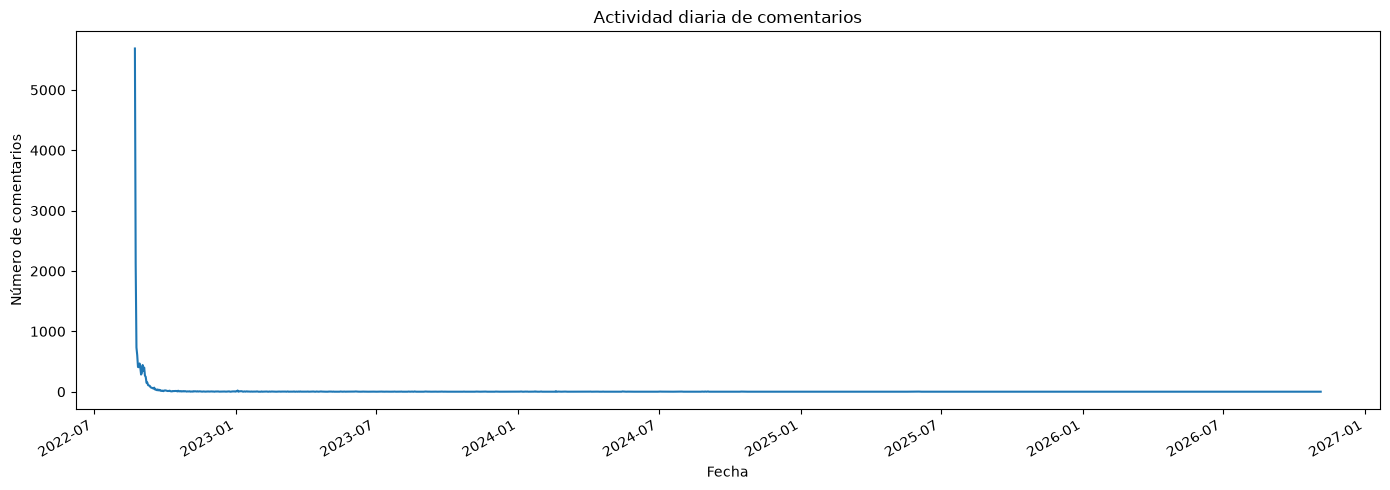

In [28]:
comments_by_day["date"] = pd.to_datetime(
    comments_by_day["date"]
)

comments_by_day.plot(
    x="date",
    y="n_comments",
    figsize=(14, 5),
    legend=False
)

plt.title("Actividad diaria de comentarios")
plt.xlabel("Fecha")
plt.ylabel("Número de comentarios")
plt.tight_layout()
plt.show()

In [29]:
cumulative = query("""
    WITH daily AS (
        SELECT
            DATE(published_at) AS date,
            COUNT(*) AS n_comments
        FROM comentarios
        GROUP BY DATE(published_at)
    ),
    cumulative AS (
        SELECT
            date,
            n_comments,
            SUM(n_comments) OVER (
                ORDER BY date
            ) AS cumulative_n,
            SUM(n_comments) OVER () AS total_n
        FROM daily
    )
    SELECT
        date,
        n_comments,
        cumulative_n,
        ROUND(
            1.0 * cumulative_n / total_n,
            6
        ) AS cumulative_pct
    FROM cumulative
    ORDER BY date
""")

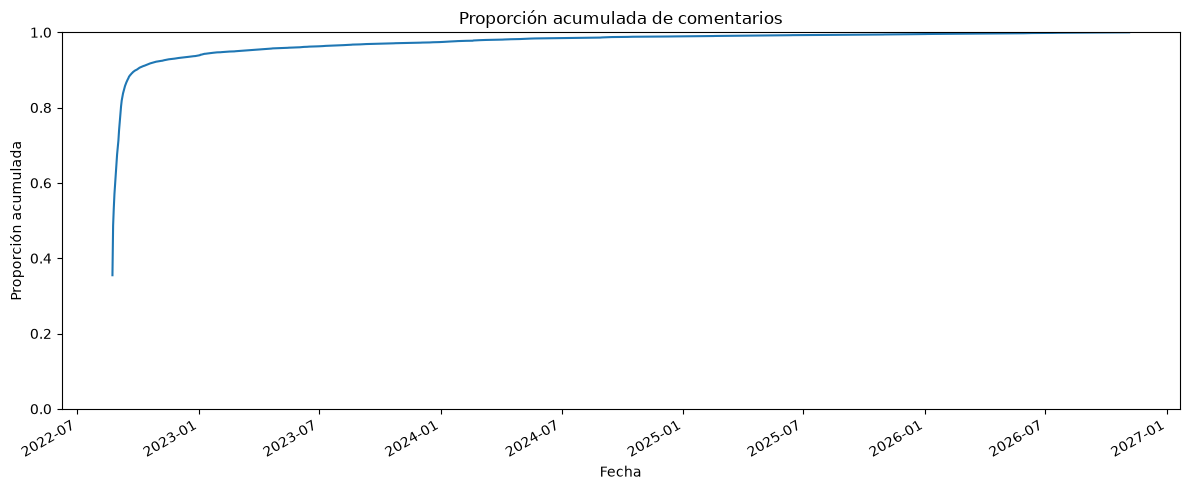

In [30]:
cumulative["date"] = pd.to_datetime(cumulative["date"])

cumulative.plot(
    x="date",
    y="cumulative_pct",
    figsize=(12, 5),
    legend=False
)

plt.title("Proporción acumulada de comentarios")
plt.xlabel("Fecha")
plt.ylabel("Proporción acumulada")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [31]:
thresholds = query("""
    WITH ordered AS (
        SELECT
            published_at,

            ROW_NUMBER() OVER (
                ORDER BY published_at
            ) AS rn,

            COUNT(*) OVER () AS total_n

        FROM comentarios
    ),

    cumulative AS (
        SELECT
            published_at,
            1.0 * rn / total_n AS cumulative_pct
        FROM ordered
    ),

    first_date AS (
        SELECT MIN(published_at) AS first_comment
        FROM comentarios
    )

    SELECT
        threshold,
        MIN(published_at) AS reached_at,

        ROUND(
            julianday(MIN(published_at))
            - julianday(
                (SELECT first_comment FROM first_date)
            ),
            3
        ) AS days_since_first

    FROM cumulative

    CROSS JOIN (
        SELECT 0.10 AS threshold
        UNION ALL SELECT 0.25
        UNION ALL SELECT 0.50
        UNION ALL SELECT 0.75
        UNION ALL SELECT 0.90
        UNION ALL SELECT 0.95
        UNION ALL SELECT 0.99
    )

    WHERE cumulative_pct >= threshold

    GROUP BY threshold

    ORDER BY threshold
""")

thresholds

,threshold,reached_at,days_since_first
0,0.10,2022-08-23T14:34:27Z,0.065
1,0.25,2022-08-23T18:11:43Z,0.216
2,0.50,2022-08-25T06:51:48Z,1.743
3,0.75,2022-09-03T12:34:57Z,10.982
4,0.90,2022-09-28T16:03:29Z,36.127
5,0.95,2023-02-27T23:58:37Z,188.457
6,0.99,2025-02-07T08:31:33Z,898.813


In [32]:
likes_summary = query("""
    SELECT
        COUNT(*) AS n,
        MIN(like_count) AS min_likes,
        ROUND(AVG(like_count), 2) AS mean_likes,
        MAX(like_count) AS max_likes,

        SUM(CASE
            WHEN like_count = 0 THEN 1
            ELSE 0
        END) AS zero_likes

    FROM comentarios
""")

likes_summary.T

,0
n,16022.00
min_likes,0.00
mean_likes,15.98
max_likes,17657.00
zero_likes,5628.00


In [33]:
like_percentiles = query("""
    WITH ordered AS (
        SELECT
            like_count,
            ROW_NUMBER() OVER (
                ORDER BY like_count
            ) AS rn,
            COUNT(*) OVER () AS n
        FROM comentarios
    )

    SELECT
        MAX(CASE
            WHEN rn >= n * 0.50
            THEN like_count
        END) AS p50,

        MAX(CASE
            WHEN rn >= n * 0.75
            THEN like_count
        END) AS p75,

        MAX(CASE
            WHEN rn >= n * 0.90
            THEN like_count
        END) AS p90

    FROM ordered
""")

In [34]:
likes_distribution = query("""
    SELECT
        CASE
            WHEN like_count = 0 THEN '0'
            WHEN like_count BETWEEN 1 AND 2 THEN '1-2'
            WHEN like_count BETWEEN 3 AND 5 THEN '3-5'
            WHEN like_count BETWEEN 6 AND 10 THEN '6-10'
            WHEN like_count BETWEEN 11 AND 50 THEN '11-50'
            WHEN like_count BETWEEN 51 AND 100 THEN '51-100'
            WHEN like_count BETWEEN 101 AND 500 THEN '101-500'
            ELSE '>500'
        END AS like_group,

        COUNT(*) AS n_comments

    FROM comentarios

    GROUP BY like_group
""")

likes_distribution

,like_group,n_comments
0,0,5628
1,1-2,5427
2,101-500,244
3,11-50,535
4,3-5,2901
5,51-100,174
6,6-10,1018
7,>500,95


In [35]:
likes_over_time = query("""
    SELECT
        strftime('%Y-%m', published_at) AS month,

        COUNT(*) AS n_comments,

        ROUND(
            AVG(like_count),
            2
        ) AS mean_likes,

        MAX(like_count) AS max_likes,

        ROUND(
            AVG(reply_count),
            2
        ) AS mean_replies

    FROM comentarios

    GROUP BY month

    ORDER BY month
""")

likes_over_time

,month,n_comments,mean_likes,max_likes,mean_replies
0,2022-08,11109,17.67,17657,0.51
1,2022-09,3349,13.90,3309,0.58
2,2022-10,329,10.30,1028,0.54
3,2022-11,139,16.17,1762,0.55
4,2022-12,108,17.24,957,0.56
5,2023-01,137,17.19,744,0.36
6,2023-02,51,6.76,159,0.31
7,2023-03,65,2.97,59,0.22
8,2023-04,58,17.76,408,0.57
9,2023-05,40,3.33,36,0.42


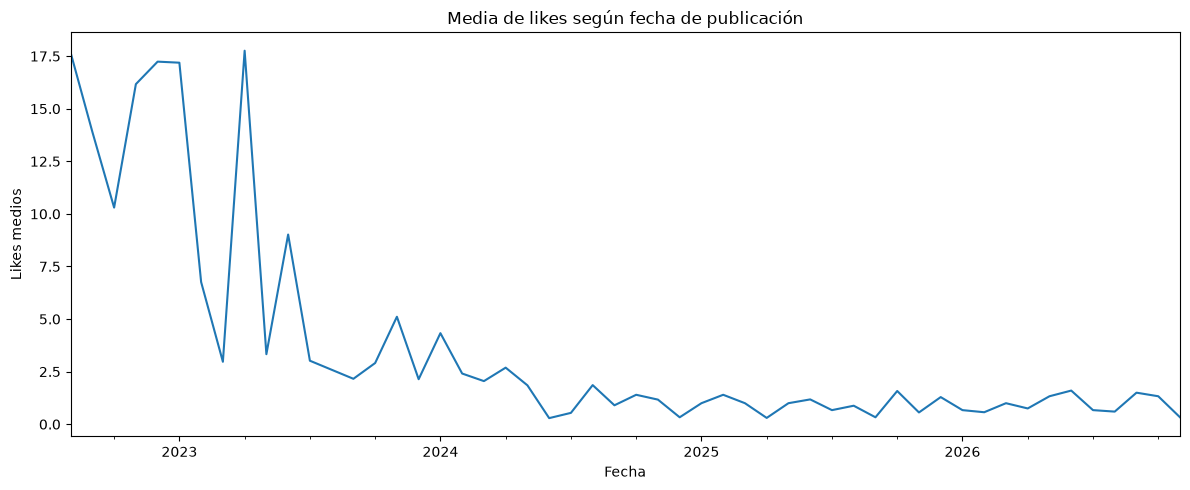

In [36]:
likes_over_time["month"] = pd.to_datetime(
    likes_over_time["month"]
)

likes_over_time.plot(
    x="month",
    y="mean_likes",
    figsize=(12, 5),
    legend=False
)

plt.title("Media de likes según fecha de publicación")
plt.xlabel("Fecha")
plt.ylabel("Likes medios")
plt.tight_layout()
plt.show()

In [42]:
comments_until_2023_09_01 = query("""
    SELECT
        DATE(published_at) AS date,
        COUNT(*) AS n_comments
    FROM comentarios
    WHERE published_at < '2022-09-01'
    GROUP BY DATE(published_at)
    ORDER BY date
""")

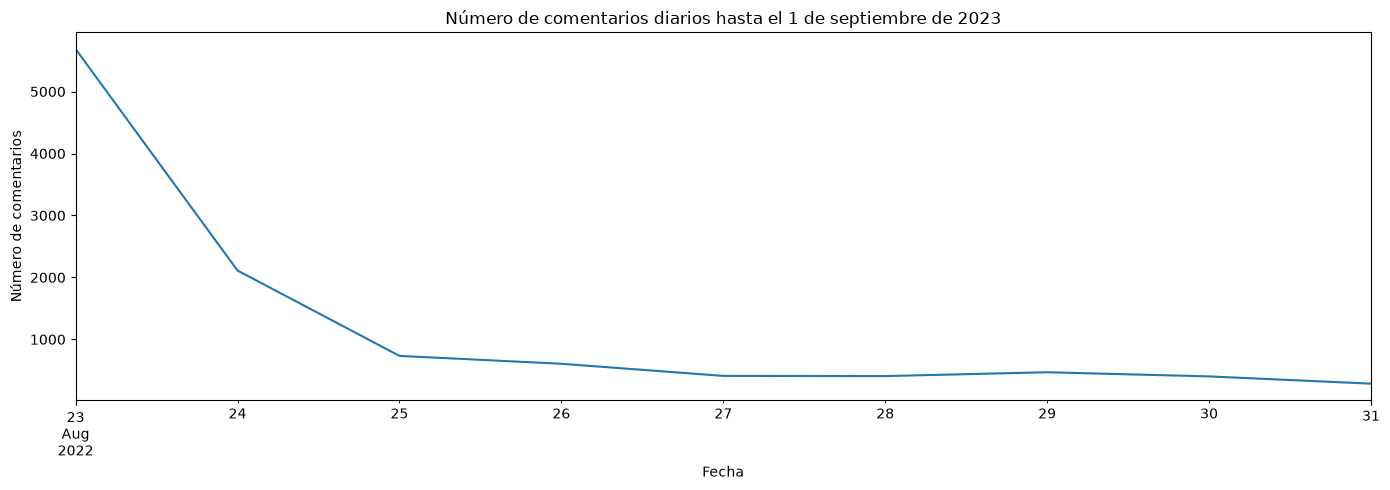

In [43]:
comments_until_2023_09_01["date"] = pd.to_datetime(
    comments_until_2023_09_01["date"]
)

comments_until_2023_09_01.plot(
    x="date",
    y="n_comments",
    figsize=(14, 5),
    legend=False
)

plt.title("Número de comentarios diarios hasta el 1 de septiembre de 2023")
plt.xlabel("Fecha")
plt.ylabel("Número de comentarios")
plt.tight_layout()
plt.show()

In [46]:
total_until_2023_09_01 = query("""
    SELECT
        COUNT(*) AS n_comments
    FROM comentarios
    WHERE published_at < '2023-09-01'
""")

total_until_2023_09_01

,n_comments
0,15508
